<a href="https://colab.research.google.com/github/hoang1015/Pham_Huy_Hoang_20233850_Assignment2/blob/main/fuzzy_logic_fixed_v3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Fuzzy rainfall detection + estimation (revised)

Mô hình hai tầng: phát hiện mưa trước, ước lượng cường độ sau. Ngưỡng và luật là giả thuyết ban đầu, **chưa được hiệu chuẩn** trên tập kiểm định độc lập. Dữ liệu có rất ít mẫu mưa; cần thêm dữ liệu để đánh giá đáng tin cậy.


In [1]:

!pip -q install scikit-fuzzy openpyxl

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import skfuzzy as fuzz
from skfuzzy import control as ctrl
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error,
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)
from google.colab import files

warnings.filterwarnings("ignore", category=RuntimeWarning)
SEED = 42

## 1. Upload và đọc dữ liệu

In [5]:
uploaded = files.upload()
if not uploaded:
    raise ValueError("Chưa upload file dữ liệu.")

filename = next(iter(uploaded))
if filename.lower().endswith((".xlsx", ".xls")):
    df = pd.read_excel(filename)
elif filename.lower().endswith(".csv"):
    df = pd.read_csv(filename)
else:
    raise ValueError("Hãy upload file Excel (.xlsx/.xls) hoặc CSV (.csv).")

print("File:", filename)
print("Kích thước dữ liệu ban đầu:", df.shape)
display(df.head())
print("Các cột:", df.columns.tolist())

Saving 9-8 9-15.xlsx to 9-8 9-15.xlsx
File: 9-8 9-15.xlsx
Kích thước dữ liệu ban đầu: (192, 12)


,time,temp,dwpt,rhum,prcp,snow,wdir,wspd,wpgt,pres,tsun,coco
0,2026-09-08 00:00:00,28,25.0,84,0.0,NaN,150.0,5,NaN,1008,NaN,2
1,2026-09-08 01:00:00,28,26.0,89,0.0,NaN,160.0,4,NaN,1008,NaN,2
2,2026-09-08 02:00:00,28,26.0,89,0.0,NaN,350.0,2,NaN,1008,NaN,2
3,2026-09-08 03:00:00,27,25.0,89,0.0,NaN,30.0,3,NaN,1008,NaN,5
4,2026-09-08 04:00:00,27,25.9,94,0.0,NaN,50.0,4,NaN,1008,NaN,5


Các cột: ['time', 'temp', 'dwpt', 'rhum', 'prcp', 'snow', 'wdir', 'wspd', 'wpgt', 'pres', 'tsun', 'coco']


## 2. Làm sạch dữ liệu và kiểm tra cột

In [6]:
required_columns = ["temp", "rhum", "wspd", "pres", "prcp"]
missing_columns = [c for c in required_columns if c not in df.columns]
if missing_columns:
    raise ValueError(
        f"Thiếu cột bắt buộc: {missing_columns}. "
        f"Các cột hiện có: {df.columns.tolist()}"
    )

data = df[required_columns].copy()
for col in required_columns:
    data[col] = pd.to_numeric(data[col], errors="coerce")

before = len(data)
data = data.replace([np.inf, -np.inf], np.nan).dropna()
data = data[(data["prcp"] >= 0) & (data["rhum"].between(0, 100))]
data = data[(data["wspd"] >= 0)]
removed = before - len(data)

if data.empty:
    raise ValueError("Không còn dòng dữ liệu hợp lệ sau khi làm sạch.")

print(f"Dòng ban đầu: {before}")
print(f"Dòng bị loại: {removed}")
print(f"Dòng hợp lệ: {len(data)}")
display(data.describe().T)

Dòng ban đầu: 192
Dòng bị loại: 0
Dòng hợp lệ: 192


,count,mean,std,min,25%,50%,75%,max
temp,192.0,27.609375,2.753107,23.0,25.0,27.0,30.0,36.0
rhum,192.0,78.489583,15.014823,50.0,66.0,79.0,94.0,100.0
wspd,192.0,5.302083,2.560758,0.0,3.0,5.0,7.0,12.0
pres,192.0,1012.130208,2.979638,1004.0,1010.0,1013.0,1014.0,1017.0
prcp,192.0,0.443229,1.830703,0.0,0.0,0.0,0.0,11.5


## 3. Tạo biến Fuzzy và membership functions

In [7]:
# Cấu hình đầu ra theo đơn vị prcp của dataset (ví dụ mm/giờ).
# Không lấy max(prcp) làm tham số: làm như vậy dùng nhãn thực tế để thiết kế mô hình.
MAX_RAINFALL = 1.0  # Sửa theo phạm vi lượng mưa cần dự đoán.
RAIN_SCORE_THRESHOLD = 0.50  # Ngưỡng heuristic; KHÔNG phải xác suất đã hiệu chuẩn.

def make_universe(series, points=201):
    lo, hi = float(series.min()), float(series.max())
    if np.isclose(lo, hi):
        pad = max(abs(lo) * 0.01, 1.0)
        lo, hi = lo - pad, hi + pad
    # Trải thêm biên để giá trị cực đại/nhỏ nhất không bị bỏ sót.
    pad = 0.01 * (hi - lo)
    return np.linspace(lo - pad, hi + pad, points)

temperature = ctrl.Antecedent(make_universe(data['temp']), 'temperature')
humidity = ctrl.Antecedent(np.linspace(0, 100, 201), 'humidity')
wind_speed = ctrl.Antecedent(make_universe(data['wspd']), 'wind_speed')
pressure = ctrl.Antecedent(make_universe(data['pres']), 'pressure')
rainfall = ctrl.Consequent(np.linspace(0, MAX_RAINFALL, 301), 'rainfall')
rain_score = ctrl.Consequent(np.linspace(0, 1, 301), 'rain_score')
print('Fuzzy variables created.')

Fuzzy variables created.


In [8]:
def create_membership_functions(variable):
    x = variable.universe
    xmin, xmax = float(x.min()), float(x.max())
    span = xmax - xmin
    q1, q2, q3 = xmin + .25*span, xmin + .50*span, xmin + .75*span
    variable['VL'] = fuzz.trimf(x, [xmin, xmin, q1])
    variable['L']  = fuzz.trimf(x, [xmin, q1, q2])
    variable['N']  = fuzz.trimf(x, [q1, q2, q3])
    variable['H']  = fuzz.trimf(x, [q2, q3, xmax])
    variable['VH'] = fuzz.trimf(x, [q3, xmax, xmax])

for variable in [temperature, humidity, wind_speed, pressure]:
    create_membership_functions(variable)

x = rainfall.universe
r = MAX_RAINFALL
rainfall['ZERO'] = fuzz.trimf(x, [0, 0, .08*r])
rainfall['VL'] = fuzz.trimf(x, [0, .10*r, .25*r])
rainfall['L']  = fuzz.trimf(x, [.10*r, .25*r, .50*r])
rainfall['N']  = fuzz.trimf(x, [.25*r, .50*r, .75*r])
rainfall['H']  = fuzz.trimf(x, [.50*r, .75*r, r])
rainfall['VH'] = fuzz.trimf(x, [.75*r, r, r])

x = rain_score.universe
rain_score['DRY'] = fuzz.trimf(x, [0, 0, .4])
rain_score['UNCERTAIN'] = fuzz.trimf(x, [.25, .5, .75])
rain_score['WET'] = fuzz.trimf(x, [.6, 1, 1])
print('Membership functions created.')

Membership functions created.


## 4. Luật Fuzzy

In [9]:
# Tầng 1: xác định tín hiệu mưa. Tất cả mức độ ẩm đều có luật bao phủ.
# Các luật là heuristic cần kiểm định, không thể suy ra mưa chắc chắn từ độ ẩm.
detection_rules = [
    ctrl.Rule(humidity['VL'] | humidity['L'], rain_score['DRY']),
    ctrl.Rule(humidity['N'], rain_score['DRY']),
    ctrl.Rule(humidity['H'] & (pressure['VL'] | pressure['L']), rain_score['WET']),
    ctrl.Rule(humidity['VH'] & (pressure['VL'] | pressure['L']), rain_score['WET']),
    ctrl.Rule(humidity['H'] & (pressure['N'] | pressure['H'] | pressure['VH']), rain_score['UNCERTAIN']),
    ctrl.Rule(humidity['VH'] & (pressure['N'] | pressure['H'] | pressure['VH']), rain_score['UNCERTAIN']),
    ctrl.Rule((humidity['H'] | humidity['VH']) & (wind_speed['H'] | wind_speed['VH']), rain_score['WET']),
]
detection_system = ctrl.ControlSystem(detection_rules)

# Tầng 2: 13 luật ước lượng cường độ cũ, bổ sung luật cho điều kiện khô.
amount_rules = [
    ctrl.Rule(humidity['VH'] & pressure['VL'] & temperature['L'], rainfall['H']),
    ctrl.Rule(humidity['VH'] & pressure['VL'] & temperature['N'], rainfall['VH']),
    ctrl.Rule(humidity['H'] & pressure['VL'] & temperature['N'], rainfall['H']),
    ctrl.Rule(humidity['H'] & pressure['L'] & wind_speed['H'], rainfall['H']),
    ctrl.Rule(humidity['VH'] & wind_speed['H'], rainfall['VH']),
    ctrl.Rule(humidity['VH'] & temperature['L'], rainfall['H']),
    ctrl.Rule(humidity['H'] & temperature['L'], rainfall['L']),
    ctrl.Rule(humidity['H'] & temperature['N'], rainfall['N']),
    ctrl.Rule(humidity['N'] & temperature['N'] & wind_speed['H'], rainfall['N']),
    ctrl.Rule(humidity['L'] & temperature['H'] & wind_speed['L'], rainfall['VL']),
    ctrl.Rule(humidity['VL'] & temperature['VH'], rainfall['VL']),
    ctrl.Rule(humidity['VL'] & pressure['VH'], rainfall['VL']),
    ctrl.Rule(humidity['L'] & pressure['VH'] & wind_speed['L'], rainfall['VL']),
    ctrl.Rule(humidity['VL'] | humidity['L'], rainfall['ZERO']),
    # Luật nền để mọi mức độ ẩm đều được bao phủ; chỉ dùng khi tầng 1 xác định mưa.
    ctrl.Rule(humidity['N'] | humidity['H'] | humidity['VH'], rainfall['VL']),
]
amount_system = ctrl.ControlSystem(amount_rules)
print('Detection rules:', len(detection_rules), '| Amount rules:', len(amount_rules))

Detection rules: 7 | Amount rules: 15


## 5. Dự đoán — xử lý trường hợp không có luật kích hoạt

In [10]:
def evaluate_system(system, row, output_name):
    sim = ctrl.ControlSystemSimulation(system, clip_to_bounds=True)
    # Mỗi tầng chỉ chấp nhận các antecedent xuất hiện trong luật của tầng đó.
    inputs = {'temperature': 'temp', 'humidity': 'rhum',
              'wind_speed': 'wspd', 'pressure': 'pres'}
    used_inputs = {v.label for v in system.fuzzy_variables
                   if isinstance(v, ctrl.Antecedent)}
    for name in used_inputs:
        sim.input[name] = float(row[inputs[name]])
    sim.compute()
    value = sim.output.get(output_name, np.nan)
    if not np.isfinite(value):
        raise ValueError(f'Không có luật kích hoạt để tạo {output_name}')
    return float(value)

predictions, scores, methods = [], [], []
inference_errors = []
for idx, row in data.iterrows():
    try:
        score = evaluate_system(detection_system, row, 'rain_score')
    except (ValueError, KeyError) as exc:
        # Không biến lỗi suy luận thành số đo mưa giả.
        score = np.nan
        inference_errors.append((idx, 'detection', str(exc)))

    scores.append(score)
    if not np.isfinite(score):
        pred, method = np.nan, 'uncovered_detection'
    elif score < RAIN_SCORE_THRESHOLD - 1e-9:
        pred, method = 0.0, 'detected_dry'
    else:
        try:
            pred = np.clip(evaluate_system(amount_system, row, 'rainfall'), 0, MAX_RAINFALL)
            method = 'fuzzy_rain'
        except (ValueError, KeyError) as exc:
            pred, method = np.nan, 'uncovered_amount'
            inference_errors.append((idx, 'amount', str(exc)))

    predictions.append(float(pred))
    methods.append(method)

data['rain_score'] = scores
data['predicted_prcp'] = predictions
data['prediction_method'] = methods
print('Status counts:')
print(data['prediction_method'].value_counts(dropna=False))
print('Uncovered rows:', data['predicted_prcp'].isna().sum())
if inference_errors:
    print('Example errors:', inference_errors[:5])
display(data.head(20))

Status counts:
prediction_method
fuzzy_rain      128
detected_dry     64
Name: count, dtype: int64
Uncovered rows: 0


,temp,rhum,wspd,pres,prcp,rain_score,predicted_prcp,prediction_method
0,28,84,5,1008,0.0,0.721056,0.451077,fuzzy_rain
1,28,89,4,1008,0.0,0.710956,0.473000,fuzzy_rain
2,28,89,2,1008,0.0,0.710956,0.473000,fuzzy_rain
3,27,89,3,1008,0.0,0.710956,0.488445,fuzzy_rain
4,27,94,4,1008,0.0,0.731867,0.512181,fuzzy_rain
5,27,94,4,1008,0.0,0.731867,0.512181,fuzzy_rain
6,26,100,3,1008,0.0,0.731867,0.538450,fuzzy_rain
7,28,89,4,1009,0.0,0.638717,0.473000,fuzzy_rain
8,29,84,4,1009,0.0,0.638717,0.420741,fuzzy_rain
9,31,79,3,1009,0.0,0.638717,0.354513,fuzzy_rain


## 6. So sánh lượng mưa thực tế và dự đoán

In [11]:
comparison = data[['prcp', 'rain_score', 'predicted_prcp', 'prediction_method']].copy()
comparison['error'] = comparison['predicted_prcp'] - comparison['prcp']
comparison['absolute_error'] = comparison['error'].abs()
display(comparison.head(20))

,prcp,rain_score,predicted_prcp,prediction_method,error,absolute_error
0,0.0,0.721056,0.451077,fuzzy_rain,0.451077,0.451077
1,0.0,0.710956,0.473000,fuzzy_rain,0.473000,0.473000
2,0.0,0.710956,0.473000,fuzzy_rain,0.473000,0.473000
3,0.0,0.710956,0.488445,fuzzy_rain,0.488445,0.488445
4,0.0,0.731867,0.512181,fuzzy_rain,0.512181,0.512181
5,0.0,0.731867,0.512181,fuzzy_rain,0.512181,0.512181
6,0.0,0.731867,0.538450,fuzzy_rain,0.538450,0.538450
7,0.0,0.638717,0.473000,fuzzy_rain,0.473000,0.473000
8,0.0,0.638717,0.420741,fuzzy_rain,0.420741,0.420741
9,0.0,0.638717,0.354513,fuzzy_rain,0.354513,0.354513


## 7. Đánh giá hồi quy

In [12]:
# Không âm thầm đưa NaN thành 0: báo tỷ lệ bao phủ trước khi tính độ chính xác.
covered = data['predicted_prcp'].notna()
print(f'Coverage: {covered.sum()}/{len(data)} ({covered.mean():.1%})')
if not covered.all():
    print('WARNING: Có dự đoán chưa được bao phủ, không được tính như mưa = 0.')

actual = data.loc[covered, 'prcp'].to_numpy(float)
predicted = data.loc[covered, 'predicted_prcp'].to_numpy(float)
if len(actual):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    baseline_mae = mean_absolute_error(actual, np.zeros_like(actual))
    print(f'MAE = {mae:.4f}; RMSE = {rmse:.4f}')
    print(f'Always-zero baseline MAE = {baseline_mae:.4f}')
    rainy = actual > 0
    if rainy.any():
        mape_rain = (np.abs(actual[rainy] - predicted[rainy]) / actual[rainy]).mean()*100
        print(f'MAPE on actually rainy samples = {mape_rain:.2f}% (n={rainy.sum()})')
else:
    print('Không có mẫu hợp lệ để tính MAE/RMSE.')

Coverage: 192/192 (100.0%)
MAE = 0.6017; RMSE = 1.8028
Always-zero baseline MAE = 0.4432
MAPE on actually rainy samples = 61.95% (n=30)


## 8. Đánh giá phát hiện mưa / không mưa

In [13]:
# Kiểm tra khả năng phát hiện mưa trên các mẫu được hệ suy luận bao phủ.
# Đây là đánh giá trên cùng tập dữ liệu, chưa phải kiểm định ngoài mẫu.
RAIN_THRESHOLD = 0.0
covered = data['predicted_prcp'].notna()
if covered.any():
    y_true = (data.loc[covered, 'prcp'] > RAIN_THRESHOLD).astype(int)
    y_pred = (data.loc[covered, 'predicted_prcp'] > RAIN_THRESHOLD).astype(int)
    print(f'Rain-score threshold: {RAIN_SCORE_THRESHOLD:.2f}')
    print(f'Accuracy : {accuracy_score(y_true, y_pred):.4f}')
    print(f'Precision: {precision_score(y_true, y_pred, zero_division=0):.4f}')
    print(f'Recall   : {recall_score(y_true, y_pred, zero_division=0):.4f}')
    print(f'F1-score : {f1_score(y_true, y_pred, zero_division=0):.4f}')
    print('Confusion matrix [[TN, FP], [FN, TP]]:')
    print(confusion_matrix(y_true, y_pred, labels=[0, 1]))
else:
    print('Không có mẫu hợp lệ để đánh giá phân loại.')

Rain-score threshold: 0.50
Accuracy : 0.4896
Precision: 0.2344
Recall   : 1.0000
F1-score : 0.3797
Confusion matrix [[TN, FP], [FN, TP]]:
[[64 98]
 [ 0 30]]


## 9. Biểu đồ và bảng các mẫu mưa

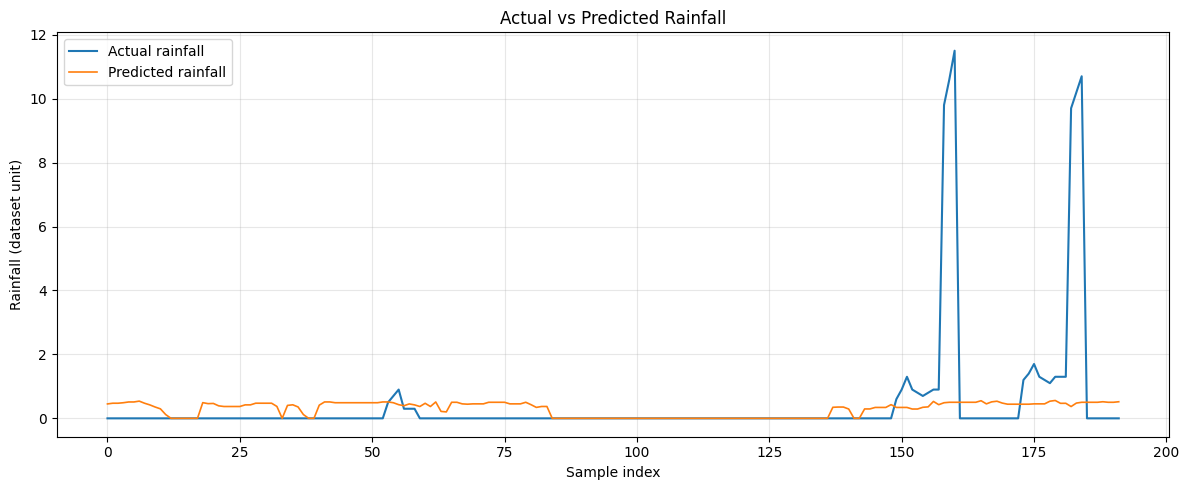

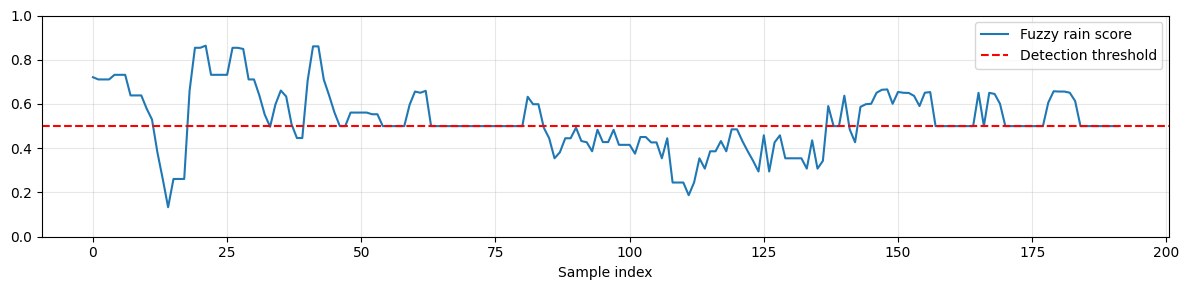

,time,temp,rhum,wspd,pres,prcp,rain_score,predicted_prcp,prediction_method,Error,PE (%)
53,2026-09-10 05:00:00,26,94,3,1010,0.5,0.553653,0.513020,fuzzy_rain,0.013020,2.603978
54,2026-09-10 06:00:00,26,89,4,1011,0.7,0.500000,0.488011,fuzzy_rain,-0.211989,30.284082
55,2026-09-10 07:00:00,27,84,3,1012,0.9,0.500000,0.427431,fuzzy_rain,-0.472569,52.507633
56,2026-09-10 08:00:00,28,79,3,1013,0.3,0.500000,0.395242,fuzzy_rain,0.095242,31.747475
57,2026-09-10 09:00:00,28,84,4,1013,0.3,0.500000,0.451077,fuzzy_rain,0.151077,50.358886
58,2026-09-10 10:00:00,29,84,4,1014,0.3,0.500000,0.420741,fuzzy_rain,0.120741,40.246864
149,2026-09-14 05:00:00,26,79,7,1013,0.6,0.601000,0.341047,fuzzy_rain,-0.258953,43.158830
150,2026-09-14 06:00:00,26,79,10,1013,0.9,0.654352,0.341047,fuzzy_rain,-0.558953,62.105887
151,2026-09-14 07:00:00,26,79,8,1013,1.3,0.650702,0.341047,fuzzy_rain,-0.958953,73.765614
152,2026-09-14 08:00:00,27,74,9,1014,0.9,0.649951,0.291291,fuzzy_rain,-0.608709,67.634294


In [14]:
plt.figure(figsize=(12, 5))
plt.plot(np.arange(len(data)), data['prcp'], label='Actual rainfall', lw=1.5)
plt.plot(np.arange(len(data)), data['predicted_prcp'], label='Predicted rainfall', lw=1.2)
plt.xlabel('Sample index')
plt.ylabel('Rainfall (dataset unit)')
plt.title('Actual vs Predicted Rainfall')
plt.legend()
plt.grid(True, alpha=.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 3))
plt.plot(np.arange(len(data)), data['rain_score'], label='Fuzzy rain score')
plt.axhline(RAIN_SCORE_THRESHOLD, color='red', linestyle='--', label='Detection threshold')
plt.ylim(0, 1)
plt.xlabel('Sample index')
plt.legend()
plt.grid(True, alpha=.3)
plt.tight_layout()
plt.show()

rain_results = data.loc[data['prcp'] > 0].copy()
rain_results['Error'] = rain_results['predicted_prcp'] - rain_results['prcp']
rain_results['Absolute Error'] = rain_results['Error'].abs()
rain_results['PE (%)'] = rain_results['Absolute Error'] / rain_results['prcp'] * 100
if 'time' in df.columns:
    rain_results['time'] = df.loc[rain_results.index, 'time']
columns_to_show = (['time'] if 'time' in rain_results else []) + [
    'temp', 'rhum', 'wspd', 'pres', 'prcp', 'rain_score',
    'predicted_prcp', 'prediction_method', 'Error', 'PE (%)'
]
display(rain_results[columns_to_show])

## 10. Xuất kết quả

In [15]:
output_file = 'fuzzy_rainfall_predictions_fixed.xlsx'
with pd.ExcelWriter(output_file, engine='openpyxl') as writer:
    data.to_excel(writer, index=True, sheet_name='Predictions')
    comparison.to_excel(writer, index=True, sheet_name='Errors')
    rain_results.to_excel(writer, index=True, sheet_name='Rainy samples')
print('Saved:', output_file)
files.download(output_file)

Saved: fuzzy_rainfall_predictions_fixed.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>